Задания по блоку Параболические уравнения

Решить тремя способами: на явном шаблоне, на неявном шаблоне, на шаблоне Кранка-Николсона

Полученные решения сравнить с частным решением

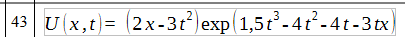
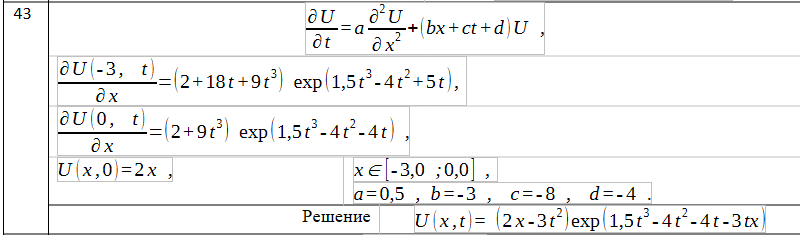

## Конечно-разностная схема

Обозначим $q(x,t)=bx+ct+d$, $x_j=x_0+jh$, $t_n=n\tau$, $\sigma=a\tau/h^2$.

Используем единую схему с весом $s$: $s=0$ - явная, $s=1$ - неявная, $s=1/2$ - схема Кранка–Николсона. Во внутренних узлах

$$-s\sigma u_{j-1}^{n+1}+(1+2s\sigma-s\tau q_j^{n+1})u_j^{n+1}-s\sigma u_{j+1}^{n+1}={}$$
$$=(1-s)\sigma u_{j-1}^{n}+[1-2(1-s)\sigma+(1-s)\tau q_j^n]u_j^n+(1-s)\sigma u_{j+1}^n.$$

Граничные условия аппроксимируем со вторым порядком по $h$, выразив $u_{xx}=(u_t-qu)/a$ через уравнение. При $r=h^2/(2a\tau)$ получаем

$$(-1-r+\tfrac{h^2q_0^{n+1}}{2a})u_0^{n+1}+u_1^{n+1}=h\varphi_0^{n+1}-r u_0^n,$$
$$-u_{N-1}^{n+1}+(1+r-\tfrac{h^2q_N^{n+1}}{2a})u_N^{n+1}=h\varphi_l^{n+1}+r u_N^n.$$

На каждом слое получается трёхдиагональная система $A u=b$, решаемая методом прогонки.

In [1]:
from math import exp
import matplotlib.pyplot as plt

# Коэффициенты уравнения.
a = 0.5
b = -3.0
c = -8.0
d = -4.0

# Расчётная область и шаги сетки.
x0 = -3.0
xk = 0.0
T = 1.0
h = 0.05    # 0.05
tau = 0.01 # 0.001
times_to_show = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
# Более частые моменты нужны только для гладких графиков норм.
error_time_step = 0.01
error_times = [round(k*error_time_step, 10)
               for k in range(round(T/error_time_step) + 1)]

def q(x, t):
    return b*x + c*t + d

def psi(x):
    return 2*x

def phi_left(t):
    return (2 + 18*t + 9*t**3)*exp(1.5*t**3 - 4*t**2 + 5*t)

def phi_right(t):
    return (2 + 9*t**3)*exp(1.5*t**3 - 4*t**2 - 4*t)

def exact_solution(x, t):
    exponent = 1.5*t**3 - 4*t**2 - 4*t - 3*t*x
    return (2*x - 3*t**2)*exp(exponent)

In [2]:
def progonka(A, B, C, D):
    # A, B, C — нижняя, главная и верхняя диагонали; D — правая часть.
    size = len(D)
    P = [0.0]*size
    Q = [0.0]*size

    P[0] = -C[0]/B[0]
    Q[0] = D[0]/B[0]

    for j in range(1, size):
        denominator = B[j] + A[j]*P[j - 1]
        P[j] = -C[j]/denominator
        Q[j] = (D[j] - A[j]*Q[j - 1])/denominator

    u = [0.0]*size
    u[-1] = Q[-1]
    for j in range(size - 2, -1, -1):
        u[j] = P[j]*u[j + 1] + Q[j]

    return u

### Вычисление одного временного слоя

Для каждого внутреннего узла основное разностное уравнение записывается как

$$A_j u_{j-1}^{n+1}+B_j u_j^{n+1}+C_j u_{j+1}^{n+1}=D_j.$$

In [3]:
def scheme_step(u_n, x_grid, t_n, s):
    # s = 0 — явная, s = 1 — неявная, s = 0.5 — Кранка–Николсона.
    N = len(x_grid) - 1
    t_n_plus_1 = t_n + tau
    sigma = a*tau/h**2
    r = h**2/(2*a*tau)

    A = [0.0]*(N + 1)
    B = [0.0]*(N + 1)
    C = [0.0]*(N + 1)
    D = [0.0]*(N + 1)

    # Уравнение на левой границе.
    B[0] = -1 - r + h**2*q(x0, t_n_plus_1)/(2*a)
    C[0] = 1
    D[0] = h*phi_left(t_n_plus_1) - r*u_n[0]

    # Уравнения во внутренних узлах.
    for j in range(1, N):
        q_n = q(x_grid[j], t_n)
        q_n_plus_1 = q(x_grid[j], t_n_plus_1)

        A[j] = -s*sigma
        B[j] = 1 + 2*s*sigma - s*tau*q_n_plus_1
        C[j] = -s*sigma

        D[j] = (
            (1 - s)*sigma*u_n[j - 1]
            + (1 - 2*(1 - s)*sigma + (1 - s)*tau*q_n)*u_n[j]
            + (1 - s)*sigma*u_n[j + 1]
        )

    # Уравнение на правой границе.
    A[N] = -1
    B[N] = 1 + r - h**2*q(xk, t_n_plus_1)/(2*a)
    D[N] = h*phi_right(t_n_plus_1) + r*u_n[N]

    # При s = 0 внутренние строки системы становятся явными.
    # Прогонка нужна для общего учёта двух граничных уравнений.
    u_n_plus_1 = progonka(A, B, C, D)
    return u_n_plus_1

### Расчёт последовательности временных слоёв

In [4]:
def solve(s):
    N = round((xk - x0)/h)
    number_of_time_steps = round(T/tau)

    x_grid = [x0 + j*h for j in range(N + 1)]
    u_n = [psi(x) for x in x_grid]

    steps_to_save = {}
    times_to_save = sorted(set(times_to_show + error_times))
    for time in times_to_save:
        steps_to_save[round(time/tau)] = time

    saved_layers = {0.0: u_n.copy()}

    for n in range(number_of_time_steps):
        t_n = n*tau
        u_n = scheme_step(u_n, x_grid, t_n, s)

        if n + 1 in steps_to_save:
            time = steps_to_save[n + 1]
            saved_layers[time] = u_n.copy()

    return x_grid, saved_layers

## Устойчивость явной схемы и сравнение

Для явной схемы требуется

$$\sigma=\frac{a\tau}{h^2}\leq\frac12, \qquad \tau\leq\frac{h^2}{2a}.$$

При $h=0.05$ максимально допустимый шаг $\tau_{max}=0.0025$. В расчёте взято $\tau=0.001$, поэтому $\sigma=0.2<1/2$. Неявная схема и схема Кранка–Николсона безусловно устойчивы.

In [5]:
sigma = a*tau/h**2
tau_max = h**2/(2*a)

# if sigma > 0.5:
#     raise ValueError('Для явной схемы нужно уменьшить шаг tau')

# Одна функция, три значения веса s.
x_grid, explicit_layers = solve(s=0.0)
_, implicit_layers = solve(s=1.0)
_, crank_nicolson_layers = solve(s=0.5)

solutions = {
    'Явная': explicit_layers,
    'Неявная': implicit_layers,
    'Кранка–Николсона': crank_nicolson_layers,
}

exact_at_T = [exact_solution(x, T) for x in x_grid]

print(f'tau_max = {tau_max:.4f}, tau = {tau:.4f}, sigma = {sigma:.3f}')
print(f'{"Схема":22} {"t":>5} {"||e||_inf":>14} {"||e||_rms":>14}')

errors_by_scheme = {}
error_norms_by_scheme = {}

for scheme_name, saved_layers in solutions.items():
    errors_by_scheme[scheme_name] = {}
    error_norms_by_scheme[scheme_name] = {}

    for time in error_times:
        exact_layer = [exact_solution(x, time) for x in x_grid]
        errors = [abs(numerical - exact)
                  for numerical, exact in zip(saved_layers[time], exact_layer)]
        max_norm = max(errors)
        rms_norm = (sum(error**2 for error in errors)/len(errors))**0.5

        errors_by_scheme[scheme_name][time] = errors
        error_norms_by_scheme[scheme_name][time] = (max_norm, rms_norm)
        if time in times_to_show:
            print(f'{scheme_name:22} {time:5.1f} {max_norm:14.6e} {rms_norm:14.6e}')

print('\nЗначения в узлах при T = 1:')
print(f'{"x":>6} {"U(x,T)":>13} {"Явная":>13} {"Неявная":>13} {"Кранка–Н.":>13}')

for j in range(0, len(x_grid), 10):
    print(
        f'{x_grid[j]:6.2f} '
        f'{exact_at_T[j]:13.6f} '
        f'{explicit_layers[T][j]:13.6f} '
        f'{implicit_layers[T][j]:13.6f} '
        f'{crank_nicolson_layers[T][j]:13.6f}'
    )

tau_max = 0.0025, tau = 0.0100, sigma = 2.000
Схема                      t      ||e||_inf      ||e||_rms
Явная                    0.0   0.000000e+00   0.000000e+00
Явная                    0.2   1.589233e+11   4.100848e+10
Явная                    0.4   5.833705e+27   1.794576e+27
Явная                    0.6   3.068510e+44   1.050139e+44
Явная                    0.8   1.927192e+61   7.105495e+60
Явная                    1.0   1.360938e+78   5.320598e+77
Неявная                  0.0   0.000000e+00   0.000000e+00
Неявная                  0.2   9.422827e-02   3.141317e-02
Неявная                  0.4   1.407248e-01   4.806338e-02
Неявная                  0.6   1.146513e-01   4.173712e-02
Неявная                  0.8   6.950615e-02   2.705103e-02
Неявная                  1.0   9.564933e-02   2.865476e-02
Кранка–Николсона         0.0   0.000000e+00   0.000000e+00
Кранка–Николсона         0.2   1.328281e-02   3.376577e-03
Кранка–Николсона         0.4   1.477733e-02   5.306839e-03
Кранка–Ник

## Решения в различные моменты времени

На каждом графике показана последовательность слоёв $t=0,0.2,\ldots,1$.

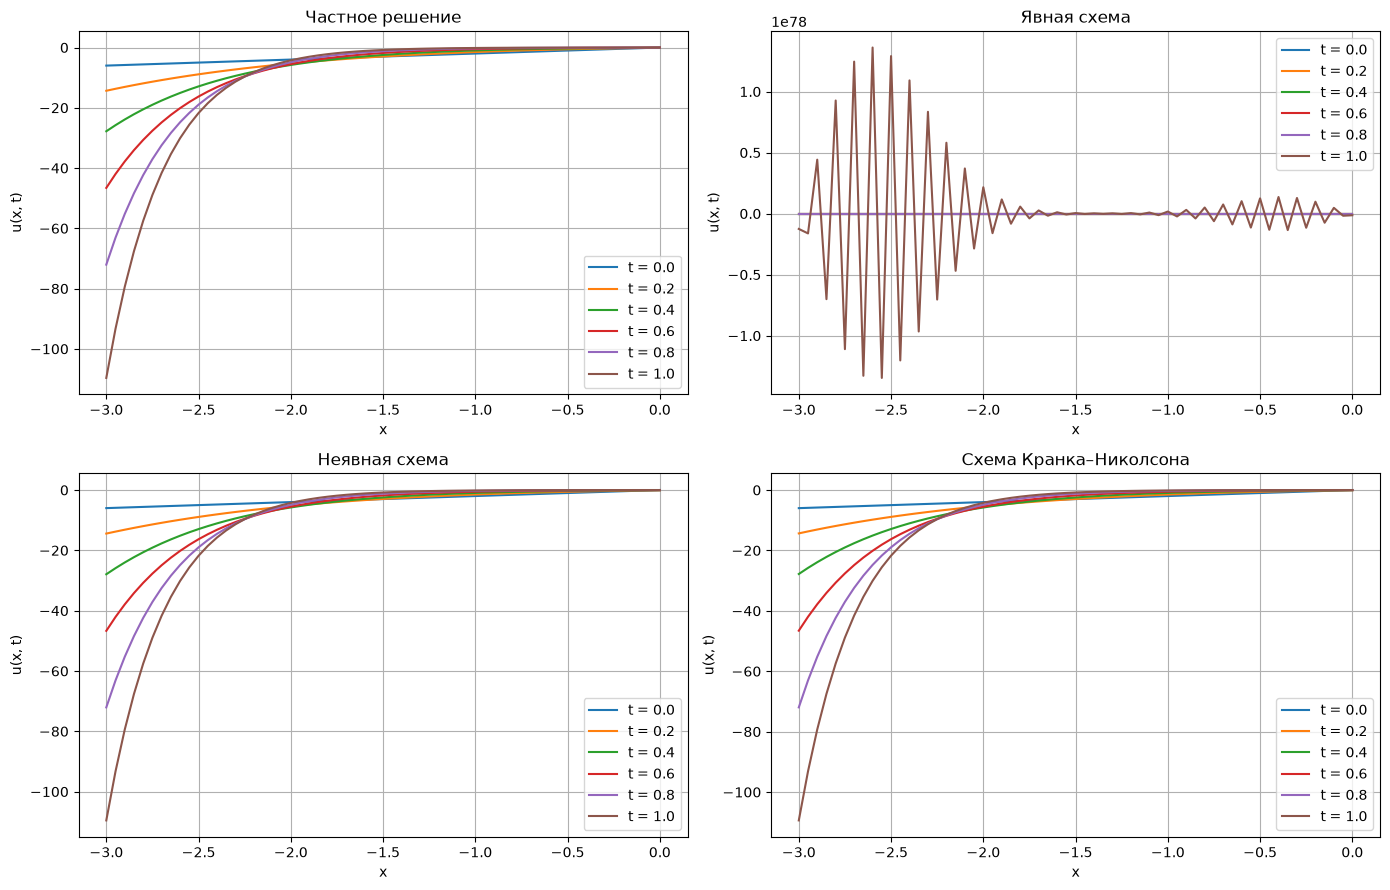

In [6]:
exact_layers = {}
for time in times_to_show:
    exact_layers[time] = [exact_solution(x, time) for x in x_grid]

plots = [
    ('Частное решение', exact_layers),
    ('Явная схема', explicit_layers),
    ('Неявная схема', implicit_layers),
    ('Схема Кранка–Николсона', crank_nicolson_layers),
]

figure = plt.figure(figsize=(14, 9))

for plot_number, (title, layers) in enumerate(plots, start=1):
    axis = figure.add_subplot(2, 2, plot_number)

    for time in times_to_show:
        axis.plot(x_grid, layers[time], label=f't = {time:.1f}')

    axis.set_title(title)
    axis.set_xlabel('x')
    axis.set_ylabel('u(x, t)')
    axis.grid(True)
    axis.legend()

figure.tight_layout()
plt.show()

## Невязка в различные моменты времени

В узле $x_j$ на слое $t^n$ невязка равна $e_j^n=|u_j^n-U(x_j,t^n)|$. Для каждого слоя вычисляются максимальная и среднеквадратичная нормы:

$$
\|e^n\|_\infty=\max_j e_j^n, \qquad
\|e^n\|_{\mathrm{rms}}=\sqrt{\frac{1}{N+1}\sum_{j=0}^{N}(e_j^n)^2}.
$$

Поскольку норма является одним числом для всего временного слоя, она строится как функция времени. Отдельно показаны максимальная и среднеквадратичная нормы; линии соответствуют разным схемам. Для этих графиков значения вычисляются через $\Delta t=0.01$.

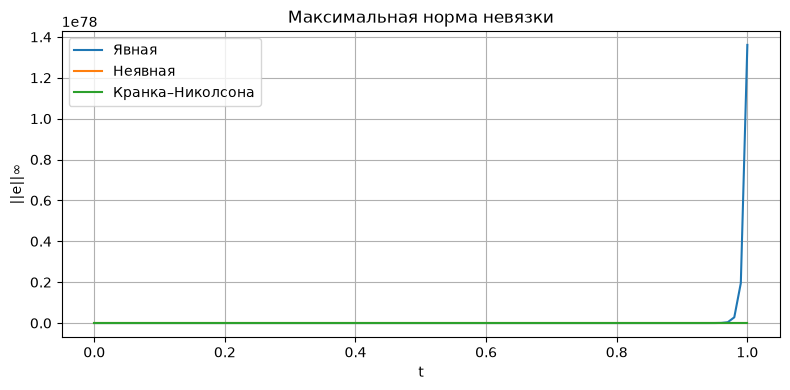

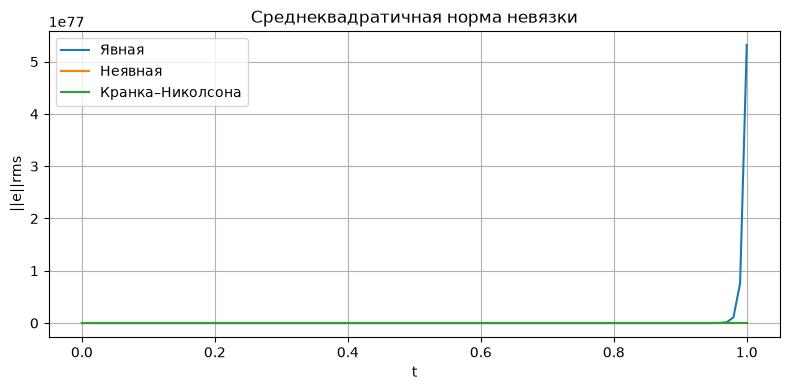

In [7]:
norm_plots = [
    ('Максимальная норма невязки', 0, '||e||∞'),
    ('Среднеквадратичная норма невязки', 1, '||e||rms'),
]

for title, norm_number, y_label in norm_plots:
    figure, axis = plt.subplots(figsize=(8, 4))

    for scheme_name, norms_by_time in error_norms_by_scheme.items():
        norm_values = [norms_by_time[time][norm_number]
                       for time in error_times]
        axis.plot(error_times, norm_values, label=scheme_name)

    axis.set_title(title)
    axis.set_xlabel('t')
    axis.set_ylabel(y_label)
    axis.grid(True)
    axis.legend()
    figure.tight_layout()
    plt.show()

### Вывод

На последовательности временных слоёв все три разностные схемы согласуются с частным решением. Максимальная ошибка достигается у левой границы, где модуль решения при $T=1$ наибольший. Явная схема использована только при выполненном условии $\sigma<1/2$; неявная схема и схема Кранка–Николсона этого ограничения не требуют.